# 02 – EDA and stationarity tests: Z4–Z6 (Team member 2)

Mirrors `02_eda_stationarity_z1_z3.ipynb`. All descriptive statistics and tests use the **training sample only** (1996-01 to 2020-12); 2021-01 onward is held out as the test period, the same cut-off the Z1–Z3 notebook uses.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore")

In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
if not (ROOT / "requirements.txt").exists():
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")

PROCESSED_DIR = ROOT / "data" / "processed"
INTERIM_DIR = ROOT / "data" / "interim"
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
for folder in (REPORTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

TRAIN_START = "1996-01-01"
TRAIN_END = "2020-12-01"     # last training month, same as Z1-Z3
TEST_START = "2021-01-01"

features = pd.read_csv(PROCESSED_DIR / "z4_z6_monthly.csv", index_col="date", parse_dates=True)
alternatives = pd.read_csv(PROCESSED_DIR / "z4_z6_alternatives_monthly.csv", index_col="date", parse_dates=True)
levels = pd.read_csv(INTERIM_DIR / "z4_z6_levels_monthly.csv", index_col="date", parse_dates=True)

train = features.loc[TRAIN_START:TRAIN_END]
test = features.loc[TEST_START:]
print(f"Full sample: {features.index.min():%Y-%m} to {features.index.max():%Y-%m} ({len(features)} months)")
print(f"Train: {train.index.min():%Y-%m} to {train.index.max():%Y-%m} ({len(train)} months)")
print(f"Test:  {test.index.min():%Y-%m} to {test.index.max():%Y-%m} ({len(test)} months)")

Full sample: 1996-01 to 2026-10 (370 months)
Train: 1996-01 to 2020-12 (300 months)
Test:  2021-01 to 2026-10 (70 months)


## Descriptive statistics (training sample)

In [3]:
desc = train.describe().T
desc["skew"] = train.skew()
desc["kurtosis"] = train.kurt()
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
z4_ip_growth,300.0,0.106,1.121,-13.232,-0.248,0.167,0.540,6.590,-5.356,71.540
z5_core_inflation,300.0,2.050,0.443,0.603,1.756,2.122,2.330,2.956,-0.691,0.512
z6_fed_funds,300.0,2.332,2.272,0.040,0.158,1.585,4.885,7.070,0.573,-1.217


## Time-series plots (dashed line = start of test period)

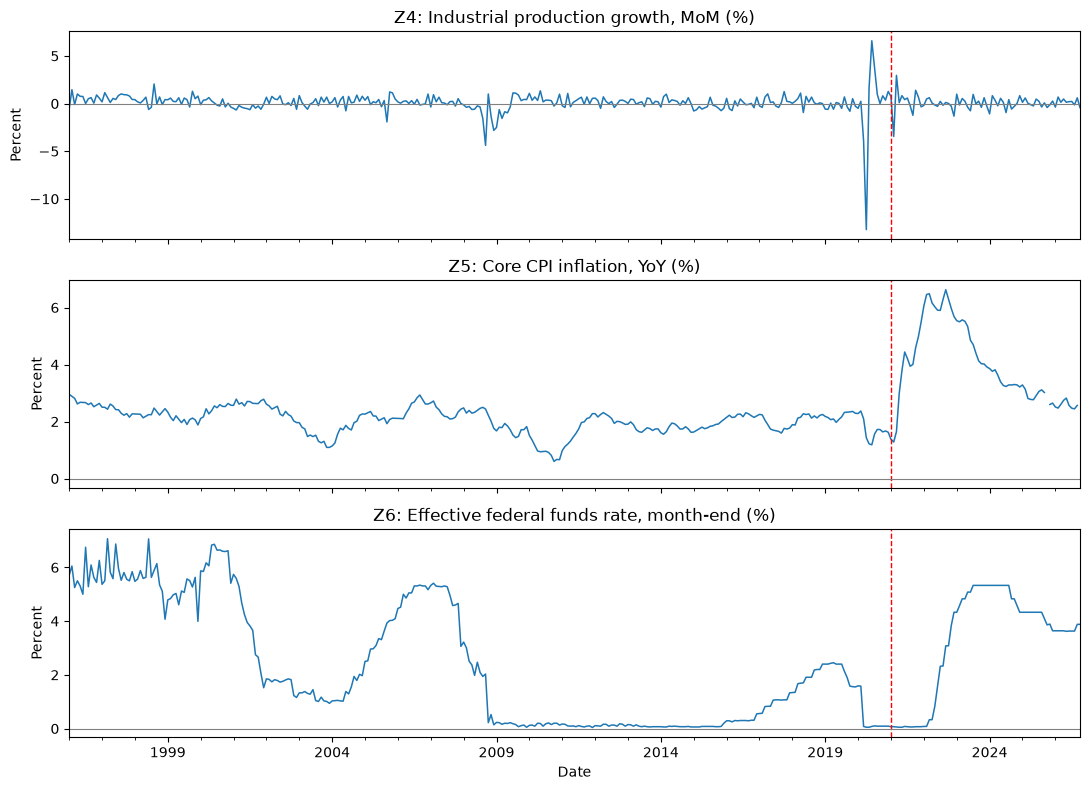

In [4]:
titles = {
    "z4_ip_growth": "Z4: Industrial production growth, MoM (%)",
    "z5_core_inflation": "Z5: Core CPI inflation, YoY (%)",
    "z6_fed_funds": "Z6: Effective federal funds rate, month-end (%)",
}
fig, axes = plt.subplots(len(titles), 1, figsize=(11, 8), sharex=True)
for ax, (col, title) in zip(axes, titles.items()):
    features[col].plot(ax=ax, linewidth=1.1)
    ax.axvline(pd.Timestamp(TEST_START), color="red", linestyle="--", linewidth=1)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel("Percent")
axes[-1].set_xlabel("Date")
plt.tight_layout()
fig.savefig(FIG_DIR / "z4_z6_timeseries.png", dpi=150)
plt.show()

## Histograms (training sample)

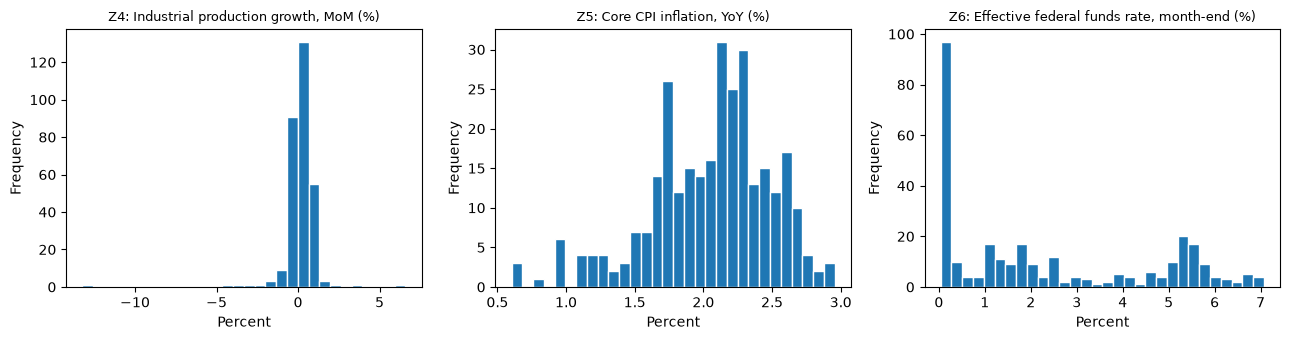

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (col, title) in zip(axes, titles.items()):
    train[col].plot(kind="hist", bins=30, ax=ax, edgecolor="white")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Percent")
plt.tight_layout()
fig.savefig(FIG_DIR / "z4_z6_histograms.png", dpi=150)
plt.show()

## Correlation heatmap (training sample)

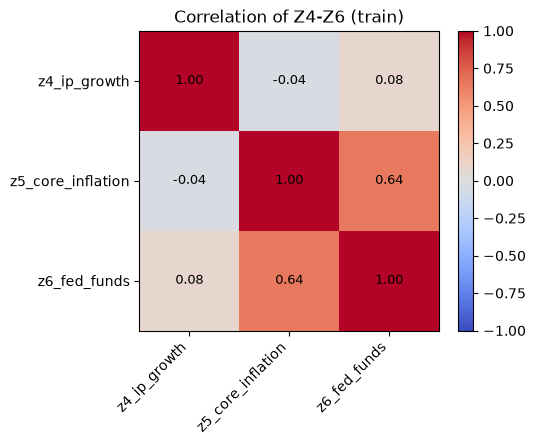

,z4_ip_growth,z5_core_inflation,z6_fed_funds
z4_ip_growth,1.000,-0.036,0.083
z5_core_inflation,-0.036,1.000,0.643
z6_fed_funds,0.083,0.643,1.000


In [6]:
corr = train.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax)
ax.set_title("Correlation of Z4-Z6 (train)")
plt.tight_layout()
fig.savefig(FIG_DIR / "z4_z6_correlation.png", dpi=150)
plt.show()
display(corr.round(3))

## Stationarity tests: ADF and KPSS

- **ADF** null: unit root (non-stationary). Reject (small p) → evidence of stationarity.
- **KPSS** null: stationary. Reject (small p) → evidence of non-stationarity.
- Both use a constant (no trend); ADF lag length by AIC, KPSS bandwidth `auto`.

In [7]:
def stationarity_tests(values, name, alpha=0.05):
    x = pd.Series(values).dropna().astype(float)
    adf_stat, adf_p, adf_lags, *_ = adfuller(x, autolag="AIC", regression="c")
    kpss_stat, kpss_p, kpss_lags, _ = kpss(x, regression="c", nlags="auto")

    adf_reject = adf_p < alpha
    kpss_reject = kpss_p < alpha
    if adf_reject and not kpss_reject:
        interpretation = "Both tests consistent with level stationarity"
    elif (not adf_reject) and kpss_reject:
        interpretation = "Both tests suggest nonstationarity"
    else:
        interpretation = "Mixed / inconclusive; inspect the time plot"

    return {
        "series": name,
        "n_obs": len(x),
        "adf_statistic": adf_stat,
        "adf_pvalue": adf_p,
        "adf_lags": adf_lags,
        "kpss_statistic": kpss_stat,
        "kpss_pvalue": kpss_p,
        "kpss_lags": kpss_lags,
        "interpretation": interpretation,
    }

results = pd.DataFrame([stationarity_tests(train[c], c) for c in train.columns]).set_index("series")
display(results.round(4))

,n_obs,adf_statistic,adf_pvalue,adf_lags,kpss_statistic,kpss_pvalue,kpss_lags,interpretation
series,,,,,,,,
z4_ip_growth,300,-12.8217,0.0000,1,0.2744,0.1000,3,Both tests consistent with level stationarity
z5_core_inflation,300,-2.9054,0.0447,13,0.6318,0.0197,10,Mixed / inconclusive; inspect the time plot
z6_fed_funds,300,-2.4215,0.1358,12,1.7036,0.0100,10,Both tests suggest nonstationarity


## Level vs transformed series

Industrial production and the core CPI are trending *levels*, so the log levels are shown next to the growth/inflation transformations; the fed funds rate is compared with its monthly change. KPSS p-values are bounded by the table in statsmodels (0.01 – 0.10).

In [8]:
tr = lambda s: s.loc[TRAIN_START:TRAIN_END]

comparison_inputs = {
    "log INDPRO (level)":              np.log(tr(levels["INDPRO"])),
    "Z4 IP growth, MoM %":             tr(features["z4_ip_growth"]),
    "Z4 alt: IP growth, YoY %":        tr(alternatives["z4_ip_yoy"]),
    "log CPILFESL (level)":            np.log(tr(levels["CPILFESL"])),
    "Z5 core inflation, YoY %":        tr(features["z5_core_inflation"]),
    "Z5 alt: core inflation, MoM %":   tr(alternatives["z5_core_inflation_mom"]),
    "Z6 fed funds level %":            tr(features["z6_fed_funds"]),
    "Z6 alt: fed funds change (pp)":   tr(alternatives["z6_fed_funds_change"]),
}
comparison = pd.DataFrame([stationarity_tests(s, n) for n, s in comparison_inputs.items()]).set_index("series")
display(comparison[["n_obs", "adf_pvalue", "kpss_pvalue", "interpretation"]].round(4))

,n_obs,adf_pvalue,kpss_pvalue,interpretation
series,,,,
log INDPRO (level),300,0.0151,0.0100,Mixed / inconclusive; inspect the time plot
"Z4 IP growth, MoM %",300,0.0000,0.1000,Both tests consistent with level stationarity
"Z4 alt: IP growth, YoY %",300,0.0314,0.0445,Mixed / inconclusive; inspect the time plot
log CPILFESL (level),300,0.6919,0.0100,Both tests suggest nonstationarity
"Z5 core inflation, YoY %",300,0.0447,0.0197,Mixed / inconclusive; inspect the time plot
"Z5 alt: core inflation, MoM %",300,0.0001,0.0452,Mixed / inconclusive; inspect the time plot
Z6 fed funds level %,300,0.1358,0.0100,Both tests suggest nonstationarity
Z6 alt: fed funds change (pp),300,0.0127,0.1000,Both tests consistent with level stationarity


## Autocorrelation (training sample)

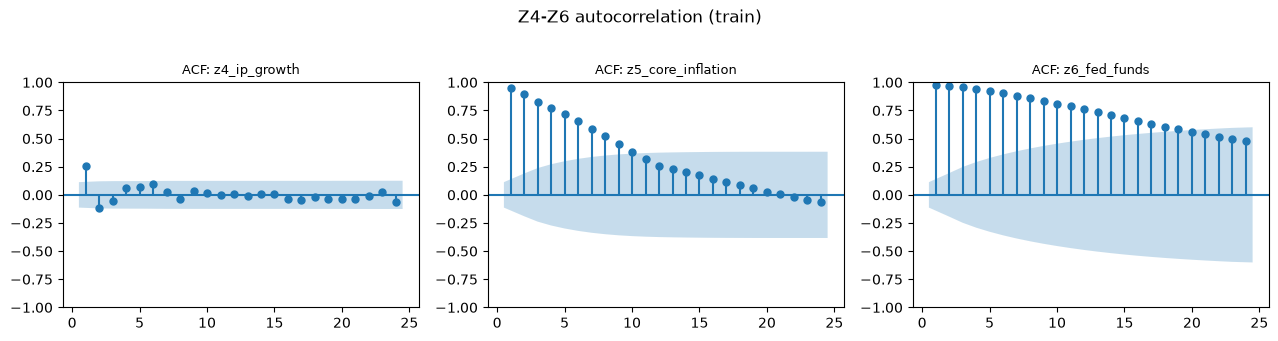

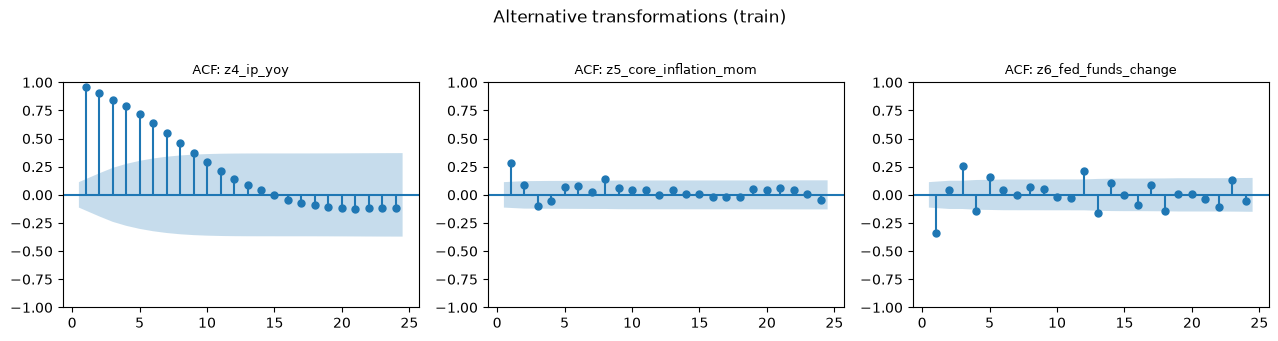

In [9]:
def acf_panel(frame, filename, title):
    fig, axes = plt.subplots(1, frame.shape[1], figsize=(4.3 * frame.shape[1], 3.3))
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, frame.columns):
        x = frame[col].dropna()
        plot_acf(x, lags=min(24, len(x) // 2 - 1), zero=False, ax=ax)
        ax.set_title(f"ACF: {col}", fontsize=9)
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

acf_panel(train, "z4_z6_acf.png", "Z4-Z6 autocorrelation (train)")
acf_panel(tr(alternatives), "z4_z6_acf_alternatives.png", "Alternative transformations (train)")

## Export results

In [10]:
desc.round(6).to_csv(REPORTS_DIR / "eda_descriptive_train_z4_z6.csv")
results.to_csv(REPORTS_DIR / "stationarity_results_train_z4_z6.csv")
comparison.to_csv(REPORTS_DIR / "stationarity_level_vs_transform_train_z4_z6.csv")

print("Saved reports to:", REPORTS_DIR.relative_to(ROOT))
for f in sorted(FIG_DIR.glob("z4_z6_*.png")):
    print("  figure:", f.relative_to(ROOT))

Saved reports to: reports
  figure: reports\figures\z4_z6_acf.png
  figure: reports\figures\z4_z6_acf_alternatives.png
  figure: reports\figures\z4_z6_correlation.png
  figure: reports\figures\z4_z6_histograms.png
  figure: reports\figures\z4_z6_timeseries.png
